# 02 · UNet: encontrar la hoja en la foto

La **UNet** es una red que mira una foto y responde, **píxel por píxel**, si ese píxel es
hoja o fondo. Su salida es una máscara: blanco = hoja, negro = fondo.

- **Aprende** de las máscaras automáticas (notebook 01), sin las rechazadas.
- **Se evalúa** con las 50 máscaras corregidas a mano, que nunca ve al entrenar.
- La comparamos con el **truco automático** (saturación): si la UNet saca mejor puntaje,
  aprendió algo más que copiar el truco.

**Dónde correrlo:** el entrenamiento va en **Google Colab con GPU**
(*Entorno de ejecución → Cambiar tipo de entorno → GPU T4*). En la compu solo se prueba
con `SMOKE=1`.

**Antes de abrirlo en Colab:** subir a `Mi unidad/Proyecto_Final_IA/` el archivo
`dataset_unet.zip`, que se genera con `python scripts/armar_dataset_unet.py`.

## 1. Preparar el entorno
En Colab conecta Google Drive (pide permiso) y descomprime los datos en `/content`.
En la compu no hace nada especial.

In [ ]:
import sys
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    sys.path.insert(0, '/content/drive/MyDrive/Proyecto_Final_IA')

import utils
entorno = utils.configurar_entorno(['dataset_unet'])
ROOT, DATA = entorno['ROOT'], entorno['DATA']

I0000 00:00:1795460346.474716   69948 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795460346.568707   69948 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795460348.189467   69948 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Entorno: compu local
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow: 2.21.0


W0000 00:00:1795460348.982629   69948 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [ ]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from skimage.io import imread
from tensorflow.keras.layers import (Input, Rescaling, Conv2D, BatchNormalization,
                                     Activation, Dropout, MaxPooling2D,
                                     Conv2DTranspose, concatenate)
from tensorflow.keras.models import Model

utils.set_estilo()
tf.keras.utils.set_random_seed(utils.SEED)   # mismos resultados cada vez que se corre

## 2. Configuración
- `SMOKE`: modo de prueba rápida (pocas fotos, 1 época). Se activa con la variable de
  entorno `SMOKE=1`; en Colab queda apagado.
- `REENTRENAR`: si ya hay un modelo guardado y está en `False`, lo carga en vez de entrenar
  de nuevo (útil si Colab cortó la sesión después de entrenar).
- `EPOCAS` es un máximo: el entrenamiento **se corta solo** cuando deja de mejorar en
  validación (*early stopping*) y se queda con la mejor época.

In [ ]:
SMOKE = os.environ.get('SMOKE') == '1'
REENTRENAR = False

EPOCAS = 1 if SMOKE else 50
PACIENCIA = 8            # épocas sin mejorar en validación antes de cortar
LR_INICIAL = 5e-4        # learning rate inicial (se reduce si val_loss se estanca)
BATCH = 16
LADO = utils.IMG_SEG     # 160
FACTOR_MANCHA = 4        # repetir mancha_bacteriana solo en train (tiene solo 60 fotos)

CARPETA = DATA / 'dataset_unet'
NOMBRE = 'unet_smoke' if SMOKE else 'unet'          # la prueba no pisa el modelo real
RUTA_MODELO = ROOT / 'models' / f'{NOMBRE}.keras'
RUTA_MODELO.parent.mkdir(exist_ok=True)
(ROOT / 'resultados').mkdir(exist_ok=True)
print('SMOKE =', SMOKE, '| modelo:', RUTA_MODELO.name)

SMOKE = False | modelo: unet.keras


## 3. Cargar los datos
`dataset_unet/` ya tiene todo listo en 160×160: en `images/` las fotos y en `masks/` sus
máscaras, **con el mismo nombre de archivo**.

| Parte | Fotos | Máscaras | Para qué |
|---|---|---|---|
| train | 1542 | automáticas | aprender |
| val | 332 | automáticas | decidir cuándo cortar el entrenamiento |
| test | 50 | **corregidas a mano** | el examen final |

Leemos los nombres desde `lista.csv` (siempre en el mismo orden), así cada foto queda con
**su** máscara. Las máscaras pasan de 0/255 a **0/1**, que es lo que espera la red.

In [ ]:
lista = pd.read_csv(CARPETA / 'lista.csv')
if SMOKE:   # prueba: unas pocas fotos de cada clase
    lista = pd.concat([lista[lista['split'] == 'test'],
                       lista[lista['split'] != 'test'].groupby(['split', 'clase']).head(10)])


def cargar(split, carpeta_mascaras='masks'):
    nombres = sorted(lista.loc[lista['split'] == split, 'archivo'])
    X = np.asarray([imread(CARPETA / split / 'images' / n) for n in nombres], dtype=np.uint8)
    Y = np.asarray([imread(CARPETA / split / carpeta_mascaras / n) for n in nombres])
    Y = (Y > 127).astype(np.float32)[..., None]      # (N, 160, 160, 1) con 0 y 1
    return X, Y, nombres


X_train, Y_train, nombres_train = cargar('train')
X_val, Y_val, _ = cargar('val')
X_test, Y_test, nombres_test = cargar('test')                    # NO se usa para entrenar
_, Y_test_auto, _ = cargar('test', 'masks_auto')                # el truco, para comparar

for nombre, X, Y in [('train', X_train, Y_train), ('val', X_val, Y_val), ('test', X_test, Y_test)]:
    print(f'{nombre:5s} fotos {X.shape}  máscaras {Y.shape}  hoja = {Y.mean():.0%} de los píxeles')

train fotos (1542, 160, 160, 3)  máscaras (1542, 160, 160, 1)  hoja = 39% de los píxeles
val   fotos (332, 160, 160, 3)  máscaras (332, 160, 160, 1)  hoja = 38% de los píxeles
test  fotos (50, 160, 160, 3)  máscaras (50, 160, 160, 1)  hoja = 37% de los píxeles


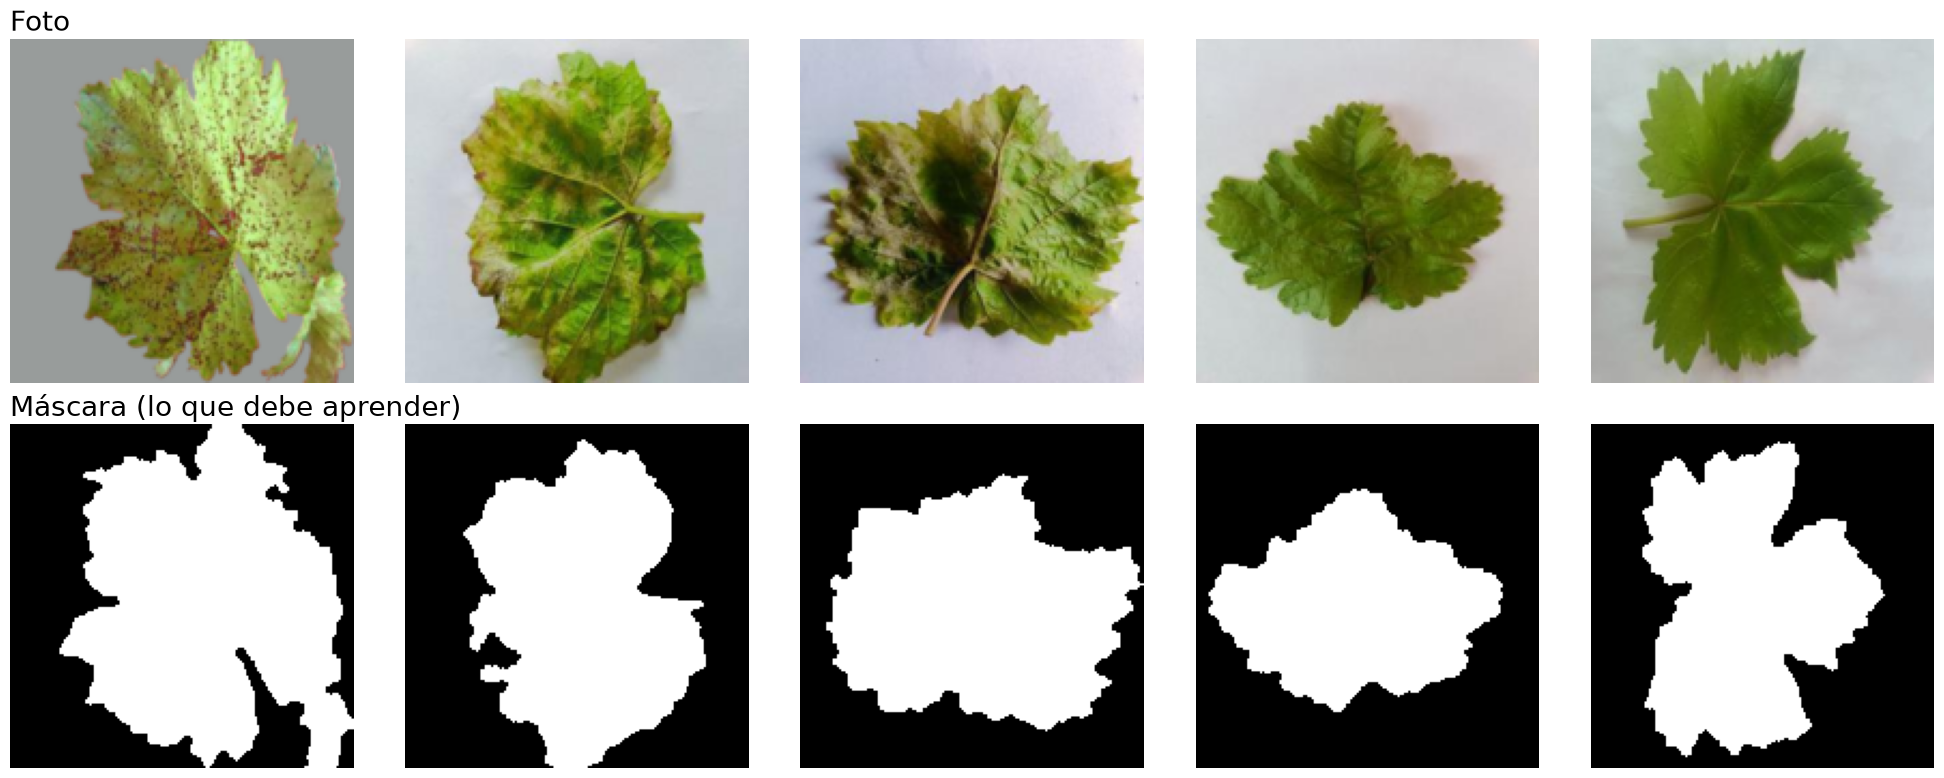

In [ ]:
fig, ax = plt.subplots(2, 5, figsize=(20, 8))
for i in range(5):
    k = i * len(X_train) // 5
    ax[0, i].imshow(X_train[k])
    ax[1, i].imshow(Y_train[k, :, :, 0], cmap='gray')
    ax[0, i].axis('off'); ax[1, i].axis('off')
ax[0, 0].set_title('Foto', loc='left'); ax[1, 0].set_title('Máscara (lo que debe aprender)', loc='left')
fig.tight_layout()
utils.guardar_figura(fig, 'unet_ejemplos_train')
plt.show()

## 4. Balanceo y aumentación de datos (solo en train)
1. **Sobremuestreo de `mancha_bacteriana`:** esta clase tiene solo 60 fotos en train (3,9%)
   y concentra los fondos grises y hojas chicas. La repetimos `FACTOR_MANCHA` veces **solo en
   train** (nunca en val ni en test).
2. **Aumentación al azar en cada época:**
   - **Espejado** horizontal/vertical y **rotación de 90°** (0°, 90°, 180°, 270°) aplicados
     por igual a foto y máscara.
   - **Cambios suaves de brillo, contraste y saturación** aplicados **solo a la foto**, para
     que la red no dependa únicamente de que la hoja sea verde intenso (ayuda con hojas
     pálidas o con manchas blanquecinas de mildiu/oídio).

In [ ]:
clase_de = dict(zip(lista['archivo'], lista['clase']))
idx_mancha = [i for i, n in enumerate(nombres_train) if clase_de[n] == 'mancha_bacteriana']
idx_extra = idx_mancha * (FACTOR_MANCHA - 1)
X_train_bal = np.concatenate([X_train, X_train[idx_extra]], axis=0) if idx_extra else X_train
Y_train_bal = np.concatenate([Y_train, Y_train[idx_extra]], axis=0) if idx_extra else Y_train
assert len(X_train_bal) == len(Y_train_bal)
print(f'Train balanceado: {len(X_train)} -> {len(X_train_bal)} fotos '
      f'(+{len(idx_extra)} copias de mancha_bacteriana)')


def aumentar(foto, mascara):
    flip_h = tf.random.uniform(()) > 0.5
    foto = tf.cond(flip_h, lambda: tf.image.flip_left_right(foto), lambda: foto)
    mascara = tf.cond(flip_h, lambda: tf.image.flip_left_right(mascara), lambda: mascara)
    flip_v = tf.random.uniform(()) > 0.5
    foto = tf.cond(flip_v, lambda: tf.image.flip_up_down(foto), lambda: foto)
    mascara = tf.cond(flip_v, lambda: tf.image.flip_up_down(mascara), lambda: mascara)
    k = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    foto = tf.image.rot90(foto, k)
    mascara = tf.image.rot90(mascara, k)

    # Cambios suaves de luz y color solo en la foto (la máscara no cambia)
    foto = tf.cast(foto, tf.float32) / 255.0
    foto = tf.image.random_brightness(foto, max_delta=0.15)
    foto = tf.image.random_contrast(foto, lower=0.85, upper=1.15)
    foto = tf.image.random_saturation(foto, lower=0.75, upper=1.25)
    foto = tf.clip_by_value(foto, 0.0, 1.0) * 255.0
    return foto, mascara


datos_train = (tf.data.Dataset.from_tensor_slices((X_train_bal, Y_train_bal))
               .shuffle(len(X_train_bal), seed=utils.SEED)
               .map(aumentar, num_parallel_calls=tf.data.AUTOTUNE)
               .batch(BATCH).prefetch(tf.data.AUTOTUNE))
datos_val = tf.data.Dataset.from_tensor_slices((X_val, Y_val)).batch(BATCH)

Train balanceado: 1542 -> 1722 fotos (+180 copias de mancha_bacteriana)


W0000 00:00:1795460443.191502   69948 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1795460443.403680   69948 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1795460443.403943   69948 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5199 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060 Ti, pci bus id: 0000:01:00.0, compute capability: 12.0a


## 5. La UNet
Partimos de la arquitectura del notebook base (`recursos/unet_pruebas_enzo.ipynb`) y le
aplicamos dos mejoras clave tras el primer entrenamiento (que había mostrado un salto brusco
en época 6 con 31M de parámetros sin normalizar):

- **Filtros reducidos (`32 → 64 → 128 → 256 → 512`):** ~7,8 millones de parámetros en vez de
  31 millones. Es 4 veces más liviana y sobreajusta menos con ~1.500 fotos.
- **BatchNormalization + inicialización `he_normal`** en cada bloque convolucional: estabiliza
  el entrenamiento y evita explosiones de gradiente.
- **Camino de bajada (codificador)** con *max pooling* (160 → 80 → 40 → 20 → 10) para aprender
  *qué* hay, y **camino de subida (decodificador)** con **conexiones de salto (`concatenate`)**
  para recuperar los bordes finos de la hoja.
- **Dropout:** apaga neuronas al azar mientras entrena para regularizar.
- **Salida:** un número entre 0 y 1 por píxel (`sigmoid`) = probabilidad de que sea hoja.

In [ ]:
def bloque(x, filtros, drop):
    x = Conv2D(filtros, (3, 3), padding='same', use_bias=False,
               kernel_initializer='he_normal')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = Dropout(drop)(x)
    x = Conv2D(filtros, (3, 3), padding='same', use_bias=False,
               kernel_initializer='he_normal')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    return x


def construir_unet():
    Image_input = Input((LADO, LADO, 3))
    inputs = Rescaling(1 / 255)(Image_input)   # pasa los píxeles de 0-255 a 0-1

    # camino de bajada
    conv1 = bloque(inputs, 32, 0.1)
    maxp1 = MaxPooling2D((2, 2))(conv1)

    conv2 = bloque(maxp1, 64, 0.1)
    maxp2 = MaxPooling2D((2, 2))(conv2)

    conv3 = bloque(maxp2, 128, 0.2)
    maxp3 = MaxPooling2D((2, 2))(conv3)

    conv4 = bloque(maxp3, 256, 0.2)
    maxp4 = MaxPooling2D((2, 2))(conv4)

    conv5 = bloque(maxp4, 512, 0.3)

    # camino de subida (con conexiones de salto)
    up6 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(conv5)
    conv6 = bloque(concatenate([up6, conv4]), 256, 0.2)

    up7 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv6)
    conv7 = bloque(concatenate([up7, conv3]), 128, 0.2)

    up8 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv7)
    conv8 = bloque(concatenate([up8, conv2]), 64, 0.1)

    up9 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(conv8)
    conv9 = bloque(concatenate([up9, conv1], axis=3), 32, 0.1)

    outputs = Conv2D(1, (1, 1), activation='sigmoid')(conv9)
    return Model(inputs=[Image_input], outputs=[outputs])

## 6. Entrenar
- **Pérdida (`utils.bce_dice_loss`):** combina `binary_crossentropy` (píxel a píxel) con
  **Dice Loss** (solapamiento global, muy parecido al IoU). Ayuda a cerrar agujeros internos
  y mejora el desempeño en hojas chicas.
- **Métrica:** **IoU** (*Intersection over Union*), de 0 a 1. Es mejor que el *accuracy*: si
  la hoja ocupa poco de la foto, decir "todo fondo" da accuracy alto pero IoU = 0.
- **Callbacks:**
  - `ReduceLROnPlateau`: baja el *learning rate* a la mitad si `val_loss` no mejora en 3 épocas,
    para afinar los bordes sin saltos bruscos.
  - `EarlyStopping`: corta si pasan 8 épocas sin mejorar en validación y restaura la mejor época.
  - `ModelCheckpoint`: guarda la mejor época en `models/unet.keras`.

**Ojo:** el IoU de val se calcula contra máscaras **automáticas**, que tienen errores.
El número que vale es el de test (sección 7), contra las corregidas a mano.

In [ ]:
if RUTA_MODELO.exists() and not REENTRENAR:
    print('Cargando el modelo ya entrenado:', RUTA_MODELO.name)
    model = tf.keras.models.load_model(
        RUTA_MODELO, custom_objects={'bce_dice_loss': utils.bce_dice_loss}
    )
else:
    model = construir_unet()
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LR_INICIAL),
        loss=utils.bce_dice_loss,
        metrics=[tf.keras.metrics.BinaryIoU(target_class_ids=[1], threshold=0.5, name='iou')],
    )
    callbacks = [
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=PACIENCIA, restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(RUTA_MODELO, monitor='val_loss', save_best_only=True),
    ]
    historia = model.fit(datos_train, validation_data=datos_val, epochs=EPOCAS, callbacks=callbacks)
    pd.DataFrame(historia.history).to_csv(ROOT / 'resultados' / f'{NOMBRE}_historia.csv', index_label='epoca')
    model.save(RUTA_MODELO)

print(f'{model.count_params():,} parámetros')

Epoch 1/50


/home/tato/venvs/proyecto-final-ia-2026/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1795460460.022696   69948 util.cc:131] oneDNN supports DT_UINT8 only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.
I0000 00:00:1795460463.247181   70364 service.cc:153] XLA service 0x7d343005fe50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795460463.247216   70364 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5060 Ti, Compute Capability 12.0a (Driver: 13.5.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795460463.373959   70364 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `

108/108 ━━━━━━━━━━━━━━━━━━━━ 44s 215ms/step - iou: 0.9272 - loss: 0.1867 - val_iou: 0.7339 - val_loss: 0.5818 - learning_rate: 5.0000e-04
Epoch 2/50
108/108 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - iou: 0.9648 - loss: 0.0802 - val_iou: 0.9139 - val_loss: 0.1704 - learning_rate: 5.0000e-04
Epoch 3/50
108/108 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - iou: 0.9678 - loss: 0.0643 - val_iou: 0.9649 - val_loss: 0.0653 - learning_rate: 5.0000e-04
Epoch 4/50
108/108 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - iou: 0.9690 - loss: 0.0578 - val_iou: 0.9516 - val_loss: 0.0919 - learning_rate: 5.0000e-04
Epoch 5/50
108/108 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - iou: 0.9679 - loss: 0.0577 - val_iou: 0.9694 - val_loss: 0.0537 - learning_rate: 5.0000e-04
Epoch 6/50
108/108 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - iou: 0.9689 - loss: 0.0544 - val_iou: 0.9673 - val_loss: 0.0567 - learning_rate: 5.0000e-04
Epoch 7/50
108/108 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - iou: 0.9692 - loss: 0.0527 - val_iou: 0.9697 - val_loss: 0.0510 - learni

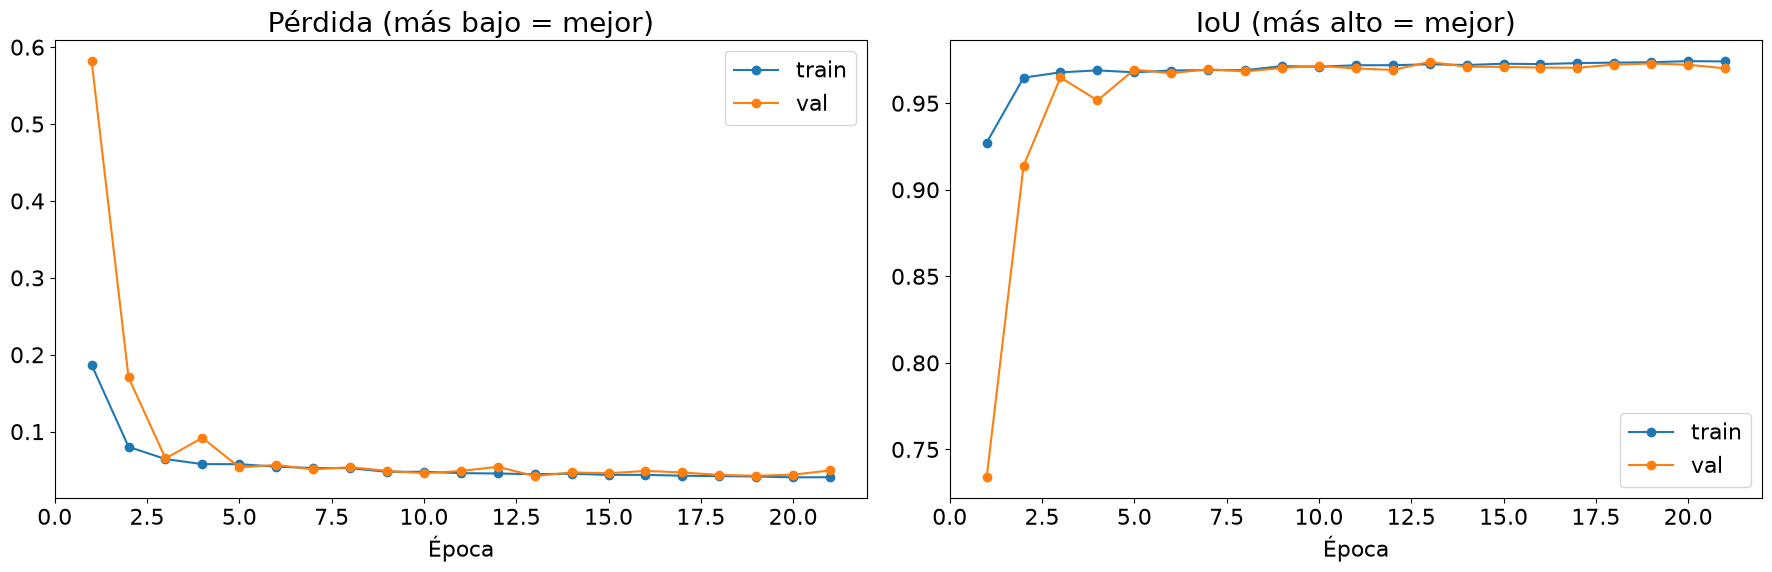

Mejor época (menor pérdida en val): 13 de 21


In [ ]:
ruta_historia = ROOT / 'resultados' / f'{NOMBRE}_historia.csv'
if ruta_historia.exists():
    h = pd.read_csv(ruta_historia)
    epocas = h['epoca'] + 1
    fig, ax = plt.subplots(1, 2, figsize=(18, 6))
    ax[0].plot(epocas, h['loss'], 'o-', label='train'); ax[0].plot(epocas, h['val_loss'], 'o-', label='val')
    ax[0].set_title('Pérdida (más bajo = mejor)'); ax[0].set_xlabel('Época'); ax[0].legend()
    ax[1].plot(epocas, h['iou'], 'o-', label='train'); ax[1].plot(epocas, h['val_iou'], 'o-', label='val')
    ax[1].set_title('IoU (más alto = mejor)'); ax[1].set_xlabel('Época'); ax[1].legend()
    fig.tight_layout()
    utils.guardar_figura(fig, f'{NOMBRE}_curvas')
    plt.show()
    print('Mejor época (menor pérdida en val):', int(h['val_loss'].idxmin()) + 1, 'de', len(h))

## 7. El examen: IoU en las 50 fotos de test
Ahora sí usamos test: la UNet predice las 50 fotos y comparamos con las máscaras corregidas
a mano. Para pasar de probabilidad a máscara, todo lo que da más de 0.5 cuenta como hoja.

Medimos lo mismo para el **truco automático**. Así sabemos si la UNet mejoró al método del
que aprendió.

In [ ]:
def iou(verdad, prediccion):
    verdad, prediccion = verdad > 0.5, prediccion > 0.5
    union = np.logical_or(verdad, prediccion).sum()
    return np.logical_and(verdad, prediccion).sum() / union if union else 1.0


P_test = model.predict(X_test, batch_size=BATCH, verbose=0)
clase_de = dict(zip(lista['archivo'], lista['clase']))
res = pd.DataFrame({
    'archivo': nombres_test,
    'clase': [clase_de[n] for n in nombres_test],
    'iou_unet': [iou(Y_test[i], P_test[i]) for i in range(len(X_test))],
    'iou_truco': [iou(Y_test[i], Y_test_auto[i]) for i in range(len(X_test))],
})
res.to_csv(ROOT / 'resultados' / f'{NOMBRE}_iou_test.csv', index=False)

tabla = res.groupby('clase')[['iou_unet', 'iou_truco']].mean()
tabla.loc['PROMEDIO'] = res[['iou_unet', 'iou_truco']].mean()
tabla.columns = ['UNet', 'Truco automático']
print(tabla.round(3).to_string())
print('\nFotos donde la UNet le gana al truco:', (res['iou_unet'] > res['iou_truco']).sum(), 'de', len(res))

                    UNet  Truco automático
clase                                     
hojas_sanas        0.969             0.983
mancha_bacteriana  0.892             0.926
mildiu             0.930             0.931
oidio              0.930             0.893
PROMEDIO           0.931             0.934

Fotos donde la UNet le gana al truco: 8 de 50


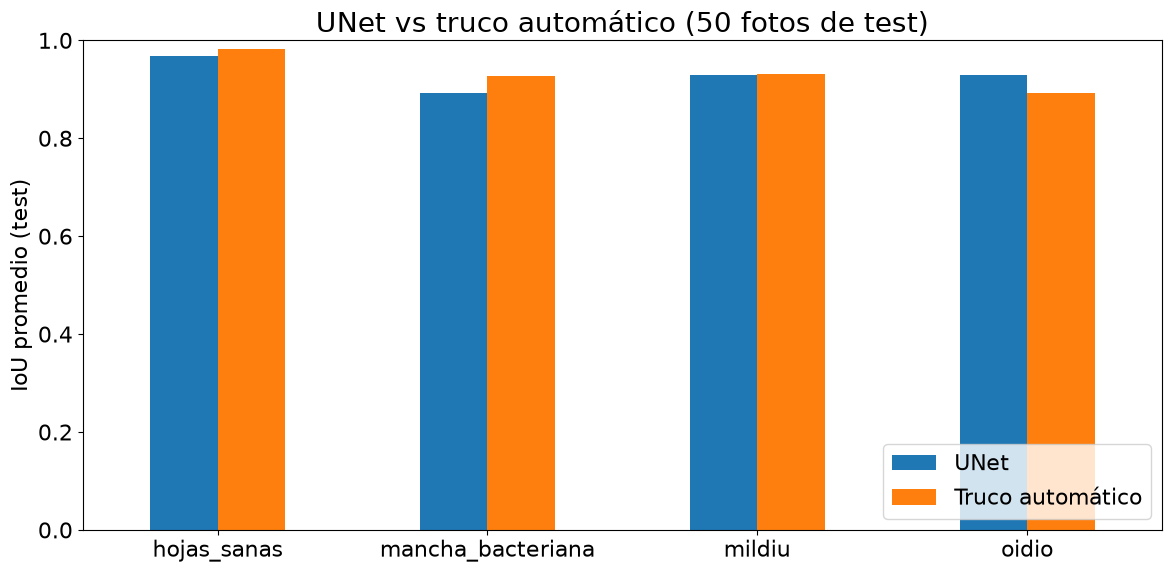

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
tabla.drop('PROMEDIO').plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1); ax.set_ylabel('IoU promedio (test)'); ax.set_xlabel('')
ax.set_title('UNet vs truco automático (50 fotos de test)')
ax.legend(loc='lower right')
fig.tight_layout()
utils.guardar_figura(fig, f'{NOMBRE}_iou_por_clase')
plt.show()

## 8. Mirar los resultados
Los números no alcanzan: hay que **ver** dónde acierta y dónde falla. Mostramos las 4 fotos
con mejor IoU y las 4 con peor. Contorno **verde** = máscara correcta (a mano);
contorno **rojo** = lo que predijo la UNet.

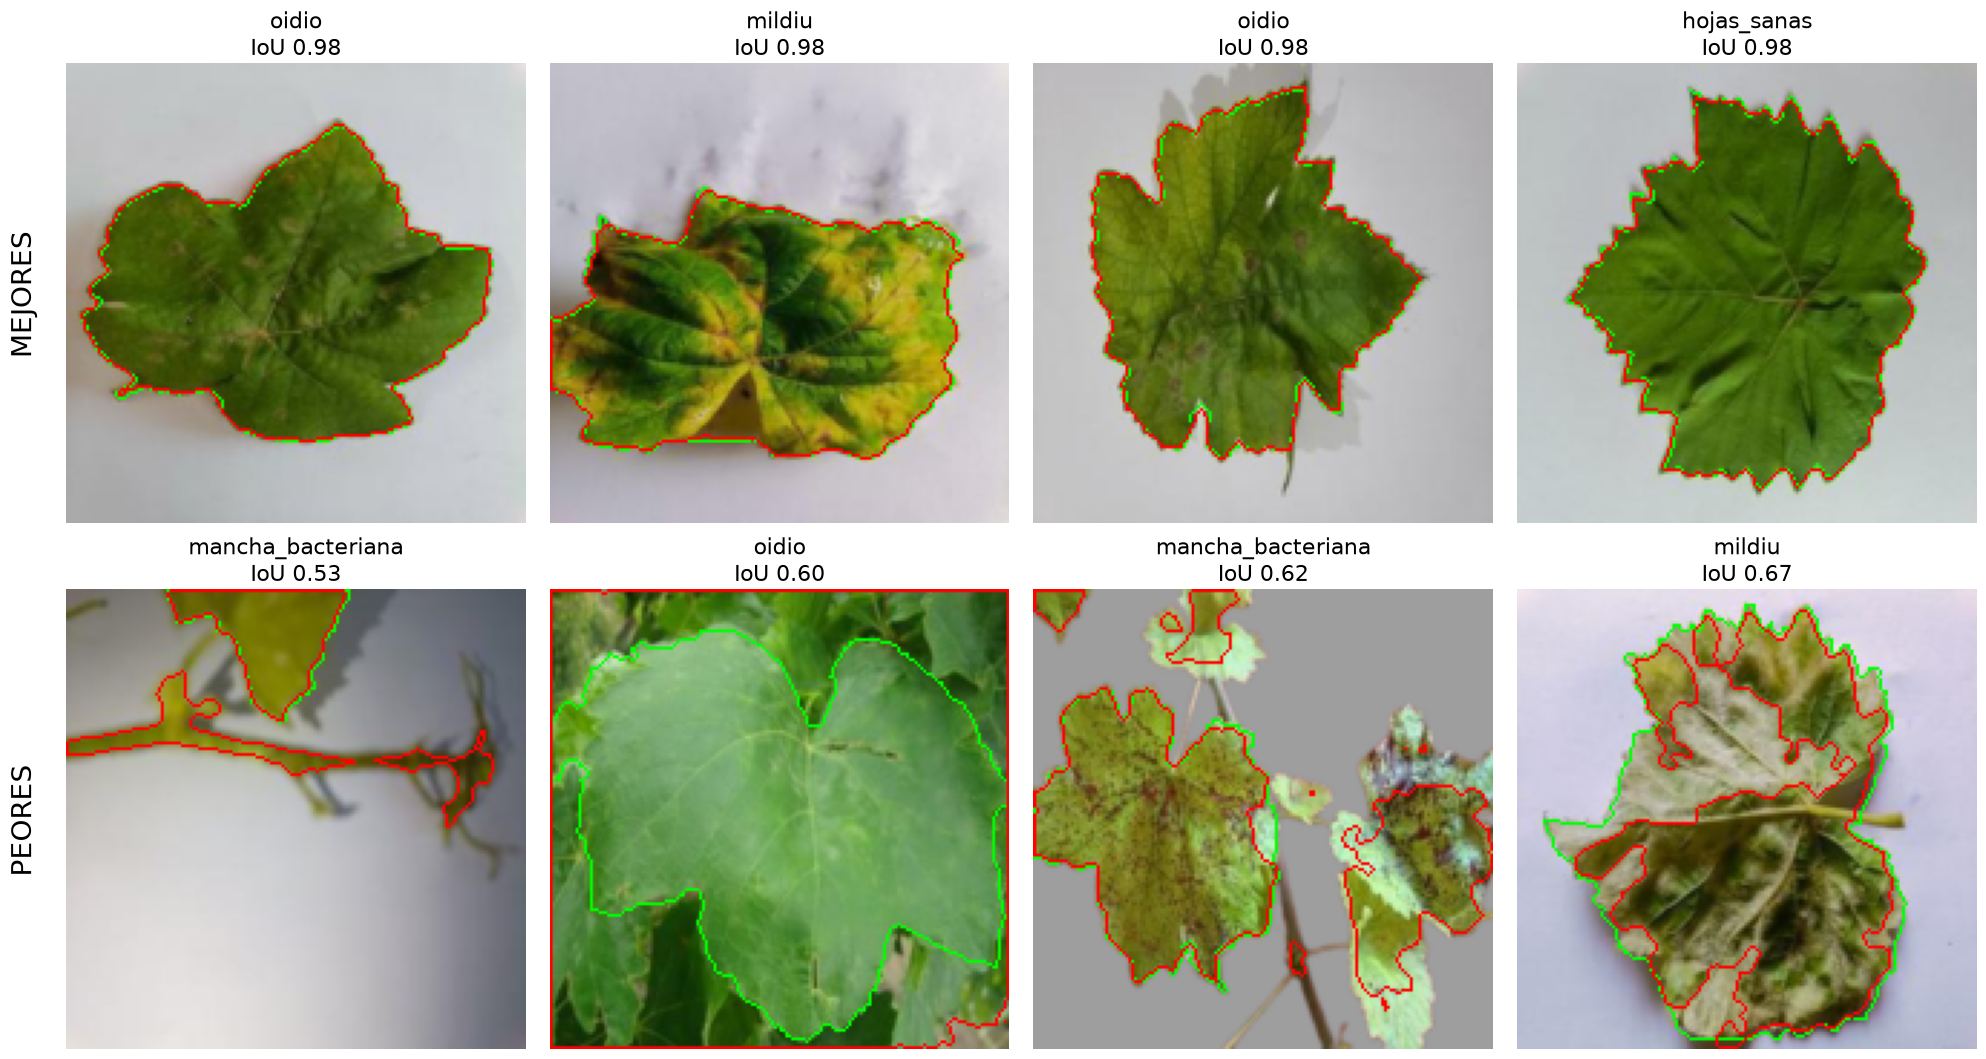

In [ ]:
import cv2


def contornos(foto, verdad, prediccion):
    img = foto.copy()
    for mascara, color in [(verdad, (0, 255, 0)), (prediccion, (255, 0, 0))]:
        bordes, _ = cv2.findContours((mascara[..., 0] > 0.5).astype(np.uint8),
                                     cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(img, bordes, -1, color, 1)
    return img


orden = res.sort_values('iou_unet').index
elegidas = list(orden[-4:][::-1]) + list(orden[:4])
fig, ax = plt.subplots(2, 4, figsize=(20, 11))
for a, i in zip(ax.flat, elegidas):
    a.imshow(contornos(X_test[i], Y_test[i], P_test[i]))
    a.set_title(f"{res.loc[i, 'clase']}\nIoU {res.loc[i, 'iou_unet']:.2f}", fontsize=16)
    a.axis('off')
ax[0, 0].text(-20, 80, 'MEJORES', rotation=90, fontsize=20, va='center')
ax[1, 0].text(-20, 80, 'PEORES', rotation=90, fontsize=20, va='center')
fig.tight_layout()
utils.guardar_figura(fig, f'{NOMBRE}_mejores_peores')
plt.show()

## 9. Conclusiones
Resultados reales en las 50 fotos de test (con máscaras corregidas a mano) tras las mejoras
de la v2 (filtros `32→512` con `BatchNormalization`, `BCE + Dice Loss`, aumentación de color
y rotaciones de 90°, y balanceo ×4 de `mancha_bacteriana` en train):

- **IoU promedio de la UNet en test:** **0.931** (mediana **0.968**; 38/50 fotos ≥ 0.95 y 43/50 ≥ 0.90).
  Subió desde **0.919** en la v1, mejorando en 45 de las 50 fotos y con un modelo 4× más liviano
  (7,77M parámetros / 90 MB vs 31M / 356 MB).
- **IoU promedio del truco automático:** **0.934** (mediana 0.985). La UNet empata en `mildiu`
  (0.930 vs 0.931), supera al truco en `oidio` (0.930 vs 0.893) y le gana con holgura en las
  fotos difíciles donde el truco falla fuerte (`Bacterial Leaf Spot_3`: 0.960 vs 0.327;
  `Powdery Mildew_395`: 0.603 vs 0.057; `Downy Mildew_852`: 0.674 vs 0.514).
- **Dónde falla más (las únicas 4 fotos debajo de 0.80):** una rama casi sin hoja
  (`Bacterial Leaf Spot_56`, 0.53), un fondo de viñedo verde sin ejemplos similares en train
  (`Powdery Mildew_395`, 0.60), una foto con 3 hojas separadas ya rechazada por la regla de
  una hoja por foto (`Bacterial Leaf Spot_97`, 0.62) y una mancha blanquecina grande tocando
  el borde (`Downy Mildew_852`, 0.67).

**Recordar:** la UNet aprendió de máscaras automáticas con errores, así que puede repetirlos.
Además, el test son solo 50 fotos y casi todas tienen fondo liso: no sabemos cómo segmenta
fotos sacadas en el viñedo.

El modelo quedó guardado en `models/unet.keras`. Lo usan el notebook 03 (para recortar las
hojas) y la app.